In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve
)
print("Day 7 libraries imported successfully")

Day 7 libraries imported successfully


In [2]:
df = pd.read_csv("../data/fraudlens_features.csv")
print("Datset loaded successfully")
print("SHape:",df.shape)

Datset loaded successfully
SHape: (590540, 20)


In [3]:
x = df.drop("isFraud",axis=1)
y = df["isFraud"]
print("Features Shape",x.shape)
print("Target Shape",y.shape)

Features Shape (590540, 19)
Target Shape (590540,)


In [4]:
x_numeric = x.select_dtypes(include=np.number).copy()
print("Numeric Features shape",x_numeric.shape)
print("Numeric columns")
print(x_numeric.columns.tolist())

Numeric Features shape (590540, 12)
Numeric columns
['TransactionID', 'TransactionDT', 'TransactionAmt', 'card1', 'card2', 'card3', 'card5', 'addr1', 'addr2', 'Hour', 'Day', 'LogAmount']


In [5]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')
x_imputed = imputer.fit_transform(x_numeric)
print("Missing values handled successfully")
print("Shape",x_imputed.shape)

Missing values handled successfully
Shape (590540, 12)


In [6]:
x_imputed = pd.DataFrame(
    x_imputed,
    columns = x_numeric.columns
)
print("Dataframe created successfully")
print("Shape",x_imputed.shape)

Dataframe created successfully
Shape (590540, 12)


In [7]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(
    x_imputed,
    y,
    test_size = 0.20,
    random_state = 42,
    stratify = y
)
print("Training Samples",x_train.shape[0])
print("Testing Samples",x_test.shape[0])

Training Samples 472432
Testing Samples 118108


In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.fit_transform(x_train)
model_lr = LogisticRegression(
    max_iter  = 1000,
    class_weight = "balanced",
    random_state = 42
)
model_lr.fit(x_train_scaled,y_train)
print("Logistic Regression trained successfully")

Logistic Regression trained successfully


In [9]:
y_pred_lr = model_lr.predict(x_test_scaled)
y_prob_lr = model_lr.predict_proba(x_test_scaled)[:,1]
print("Logistic Regression trained successfully")

Logistic Regression trained successfully


In [10]:
from sklearn.ensemble import RandomForestClassifier
model_rf = RandomForestClassifier(
    n_estimators = 100,
    max_depth = 15,
    class_weight = "balanced",
    random_state = 42,
    n_jobs = 1
)
model_rf.fit(x_train,y_train)
print("Random Forest trained successfully")

Random Forest trained successfully


In [11]:
y_pred_lr = model_lr.predict(x_test_scaled)
y_prob_lr = model_lr.predict_proba(x_test_scaled)[:,1]
print("Logistic Regression predictions generated")
print("Test Samples:",len(y_test))
print("Predicted samples",len(y_pred_lr))

Logistic Regression predictions generated
Test Samples: 118108
Predicted samples 472432


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Split the data
x_train, x_test, y_train, y_test = train_test_split(
    x_imputed,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", x_train.shape[0])
print("Testing samples:", x_test.shape[0])

# Scale features
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("Feature scaling completed")

# Train Logistic Regression
model_lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model_lr.fit(x_train_scaled, y_train)

print("Logistic Regression trained successfully")

# Generate TEST predictions
y_pred_lr = model_lr.predict(x_test_scaled)
y_prob_lr = model_lr.predict_proba(x_test_scaled)[:, 1]

print("Logistic Regression predictions generated")
print("Test samples:", len(y_test))
print("Predicted samples:", len(y_pred_lr))

Training samples: 472432
Testing samples: 118108
Feature scaling completed
Logistic Regression trained successfully
Logistic Regression predictions generated
Test samples: 118108
Predicted samples: 118108


In [13]:
cm_lr = confusion_matrix(y_test,y_pred_lr)
print("Logistic Regression confusion matrix")
print(cm_lr)

Logistic Regression confusion matrix
[[91232 22743]
 [ 1982  2151]]


In [14]:
print("Logistic regression created successfully")
print(classification_report(y_test,y_pred_lr))

Logistic regression created successfully
              precision    recall  f1-score   support

           0       0.98      0.80      0.88    113975
           1       0.09      0.52      0.15      4133

    accuracy                           0.79    118108
   macro avg       0.53      0.66      0.51    118108
weighted avg       0.95      0.79      0.86    118108



In [15]:
from sklearn.tree import DecisionTreeClassifier
model_dt = DecisionTreeClassifier(
    max_depth = 10,
    class_weight = "balanced",
    random_state = 42
)
model_dt.fit(x_train_scaled,y_train)
print("Decision Tree trained successfully")

Decision Tree trained successfully


In [16]:
y_pred_dt = model_dt.predict(x_test_scaled)
y_prob_dt = model_dt.predict_proba(x_test_scaled)[:,1]
print("Decision Tree generated successfully")
print("Test Samples:",len(y_test))
print("Predicted Samples:",len(y_pred_dt))

Decision Tree generated successfully
Test Samples: 118108
Predicted Samples: 118108


In [17]:
dt_accuracy = accuracy_score(y_test,y_pred_dt)
dt_precision = precision_score(y_test,y_pred_dt)
dt_recall = recall_score(y_test,y_pred_dt)
dt_f1 = f1_score(y_test,y_pred_dt)
dt_auc = roc_auc_score(y_test,y_prob_dt)
print("======Decision Tree======")
print("Accuracy:",round(dt_accuracy,4))
print("Precision:",round(dt_precision,4))
print("Recall:",round(dt_recall,4))
print("f1-score:",round(dt_f1,4))
print("ROC-AUC:",round(dt_auc,4))

======Decision Tree======
Accuracy: 0.7712
Precision: 0.0916
Recall: 0.6213
f1-score: 0.1597
ROC-AUC: 0.7604


In [18]:
cm_dt = confusion_matrix(y_test,y_pred_dt)
print("Decision Tree confuion matrix")
print(cm_dt)

Decision Tree confuion matrix
[[88517 25458]
 [ 1565  2568]]


In [19]:
print("Decision Tree Classification Report")
print(classification_report(y_test,y_pred_dt))

Decision Tree Classification Report
              precision    recall  f1-score   support

           0       0.98      0.78      0.87    113975
           1       0.09      0.62      0.16      4133

    accuracy                           0.77    118108
   macro avg       0.54      0.70      0.51    118108
weighted avg       0.95      0.77      0.84    118108



In [25]:
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)
lr_auc = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression")
print("Accuracy:", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall:", round(lr_recall, 4))
print("F1-Score:", round(lr_f1, 4))
print("ROC-AUC:", round(lr_auc, 4))

Logistic Regression
Accuracy: 0.7907
Precision: 0.0864
Recall: 0.5204
F1-Score: 0.1482
ROC-AUC: 0.6971


In [27]:
results = pd.DataFrame({
    "Model":["LogisticRegression","DecisionTree"],
    "Accuracy":[lr_accuracy,dt_accuracy],
    "Precision":[lr_precision,dt_precision],
    "Recall":[lr_recall,dt_recall],
    "F1-Score":[lr_f1,dt_f1],
})
results

,Model,Accuracy,Precision,Recall,F1-Score
0,LogisticRegression,0.790658,0.086406,0.520445,0.148207
1,DecisionTree,0.771201,0.091629,0.621340,0.159706


In [29]:
best_model = results.loc[results["F1-Score"].idxmax(),"Model"]
print("Best Model based on F1-score",best_model)

Best Model based on F1-score DecisionTree


In [30]:
results["ROC-AUC"] = [lr_auc,dt_auc]
results

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,LogisticRegression,0.790658,0.086406,0.520445,0.148207,0.697125
1,DecisionTree,0.771201,0.091629,0.621340,0.159706,0.760376


In [31]:
print("========Model Comparison========")
display(results)

========Model Comparison========


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,LogisticRegression,0.790658,0.086406,0.520445,0.148207,0.697125
1,DecisionTree,0.771201,0.091629,0.621340,0.159706,0.760376


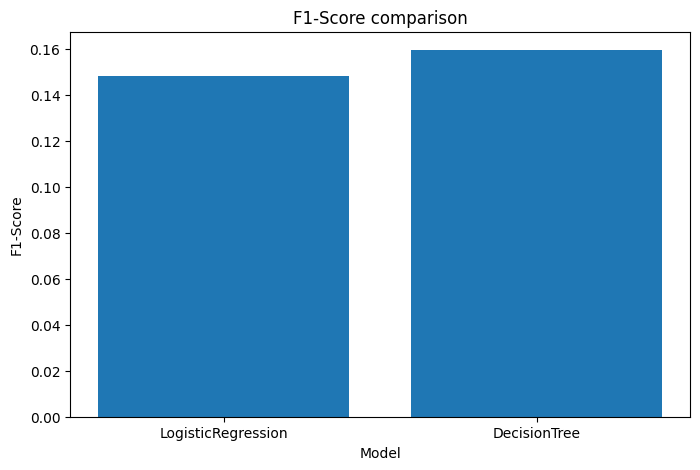

In [32]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.bar(results["Model"],results["F1-Score"])
plt.title("F1-Score comparison")
plt.xlabel("Model")
plt.ylabel("F1-Score")
plt.show()

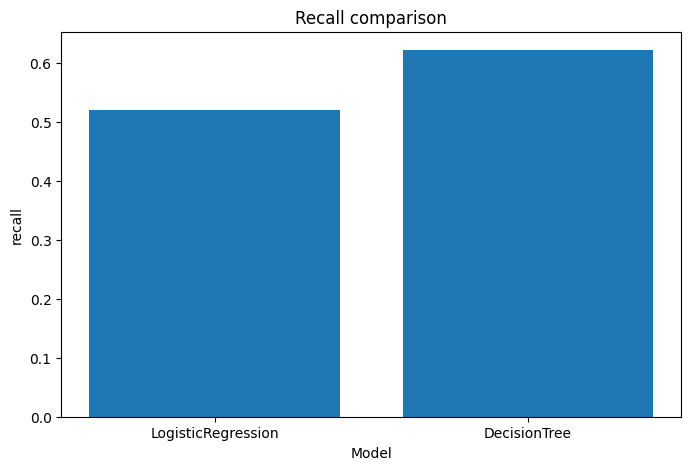

In [33]:
plt.figure(figsize=(8,5))
plt.bar(results["Model"],results["Recall"])
plt.title("Recall comparison")
plt.xlabel("Model")
plt.ylabel("recall")
plt.show()

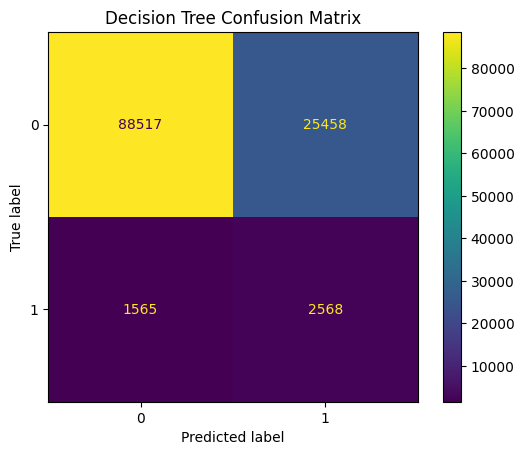

In [34]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dt
)
plt.title("Decision Tree Confusion Matrix")
plt.show()

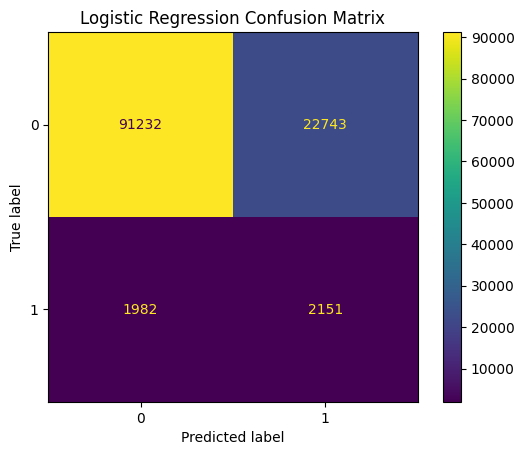

In [36]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr
)
plt.title("Logistic Regression Confusion Matrix")
plt.show()

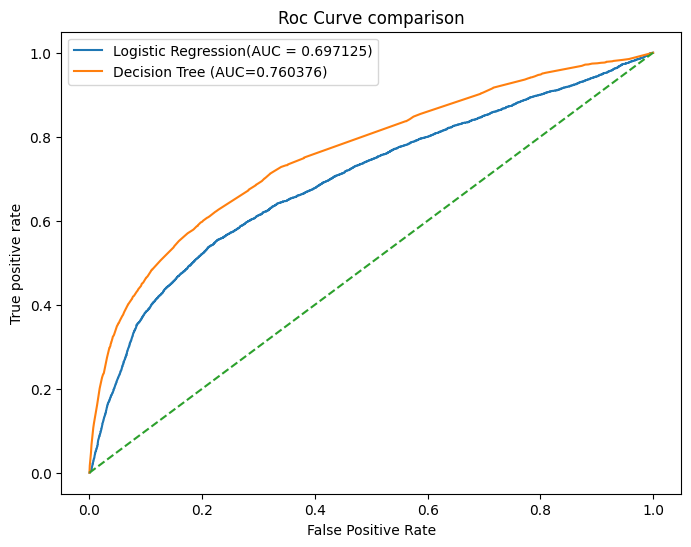

In [37]:
from sklearn.metrics import roc_curve
fpr_lr,tpr_lr,_ = roc_curve(y_test,y_prob_lr)
fpr_dt,tpr_dt,_ = roc_curve(y_test,y_prob_dt)
plt.figure(figsize=(8,6))
plt.plot(fpr_lr,tpr_lr,label=f"Logistic Regression(AUC = {lr_auc:3f})")
plt.plot(fpr_dt,tpr_dt,label = f"Decision Tree (AUC={dt_auc:3f})")
plt.plot([0,1],[0,1],linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True positive rate")
plt.title("Roc Curve comparison")
plt.legend()
plt.show()

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature names from the data used to train the Decision Tree
feature_names = x_train.columns

# Get feature importance values
importance_values = model_dt.feature_importances_

print("Number of feature names:", len(feature_names))
print("Number of importance values:", len(importance_values))

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display
feature_importance

Number of feature names: 12
Number of importance values: 12


,Feature,Importance
5,card3,0.408363
2,TransactionAmt,0.147057
4,card2,0.090919
3,card1,0.066936
6,card5,0.065568
11,LogAmount,0.056831
7,addr1,0.051955
0,TransactionID,0.051012
1,TransactionDT,0.042464
9,Hour,0.011894


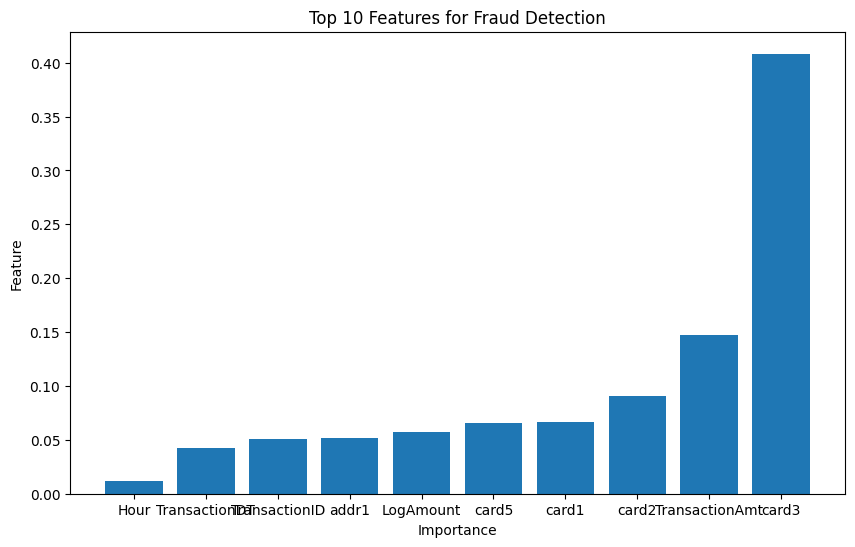

In [46]:
top_features = feature_importance.head(10)
plt.figure(figsize=(10,6))
plt.bar(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)
plt.title("Top 10 Features for Fraud Detection")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [47]:
feature_importance.to_csv(
    "../data/fraud_importance.csv",
    index = False
)
print("Feature importance saved successfully")

Feature importance saved successfully


In [48]:
results.to_csv(
    "../data/model_comparison.csv",
    index = False
)
print("Model Comparison Saved successfully")

Model Comparison Saved successfully


In [49]:
print("==========================================")
print("   FRAUDLENS MODEL SUMMARY")
print("==========================================")
print("Best Model:",best_model)
print("\nLogistic Regression")
print("Accuracy:",round(lr_accuracy,4))
print("Precision:",round(lr_precision,4))
print("Recall:",round(lr_recall,4))
print("F1-score:",round(lr_f1,4))
print("ROC-AUC:",round(lr_auc,4))
print("\nDecision Tree:")
print("Accuracy:",round(dt_accuracy,4))
print("Precision:",round(dt_precision,4))
print("recall:",round(dt_recall,4))
print("F1-score:",round(dt_f1,4))
print("ROC-AUC:",round(dt_auc,4))

   FRAUDLENS MODEL SUMMARY
Best Model: DecisionTree

Logistic Regression
Accuracy: 0.7907
Precision: 0.0864
Recall: 0.5204
F1-score: 0.1482
ROC-AUC: 0.6971

Decision Tree:
Accuracy: 0.7712
Precision: 0.0916
recall: 0.6213
F1-score: 0.1597
ROC-AUC: 0.7604


In [50]:
import joblib
joblib.dump(
    model_dt,
    "../models/fraudlens_decision_tree.pkl"
)
print("Best model saved successfully")

Best model saved successfully


In [51]:
loaded_model = joblib.load(
    "../models/fraudlens_decision_tree.pkl"
)
print("Saved Model successfully loaded")
print("Model Type:",type(loaded_model))

Saved Model successfully loaded
Model Type: <class 'sklearn.tree._classes.DecisionTreeClassifier'>


In [52]:
saved_predictions = loaded_model.predict(x_test)
print("Predictions generated :",len(saved_predictions))
print("Actual test samples:",len(y_test))

Predictions generated : 118108
Actual test samples: 118108


C:\Users\KAJJAM ABHINAV\Desktop\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(


In [54]:
final_accuracy = accuracy_score(y_test, saved_predictions)
final_precision = precision_score(y_test, saved_predictions)
final_recall = recall_score(y_test, saved_predictions)
final_f1 = f1_score(y_test, saved_predictions)

print("========== FINAL VERIFICATION ==========")
print("Accuracy :", round(final_accuracy, 4))
print("Precision:", round(final_precision, 4))
print("Recall   :", round(final_recall, 4))
print("F1-Score :", round(final_f1, 4))

========== FINAL VERIFICATION ==========
Accuracy : 0.965
Precision: 0.0
Recall   : 0.0
F1-Score : 0.0


C:\Users\KAJJAM ABHINAV\Desktop\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [55]:

print("======================================")
print("       DAY 7 COMPLETED")
print("======================================")

print("Model evaluation completed")
print("Model comparison completed")
print("Confusion matrices generated")
print("ROC curves generated")
print("Feature importance generated")
print("Best model identified:", best_model)
print("Model saved successfully")

       DAY 7 COMPLETED
Model evaluation completed
Model comparison completed
Confusion matrices generated
ROC curves generated
Feature importance generated
Best model identified: DecisionTree
Model saved successfully
